# **Social and Technological Networks**

This notebook builds from `data/hero-network.csv` dataset. It describes a hero-hero appearance graph.

Each row of the file is one co-appearance of two heroes in one comic, so the same pair appears once for every comic they share.

First step: cleaning the dataset:

1. Strip leading/trailing whitespace from hero names  
2. Drop self-loops (a hero paired with themself)  
3. Merge duplicate pairs into one undirected edge, with `weight` = number of co-appearances  
4. List hero names that do not match `data/nodes.csv`, with a suggested fix for each  
5. Rename those nodes in the graph (in code only; the CSV files are not modified)  
6. Draw the graph

In [17]:
from time import perf_counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

DATA_DIR = "./data"

print("NetworkX version:", nx.__version__)
print("pandas version:", pd.__version__)

NetworkX version: 3.2.1
pandas version: 2.3.3


## Data loading and cleaning

### 0. Load the raw data

`nodes.csv` and `edges.csv` are only used as reference lists of valid hero names.

In [20]:
hero_network = pd.read_csv(DATA_DIR + "/hero-network.csv")
nodes = pd.read_csv(DATA_DIR + "/nodes.csv")
hero_comic = pd.read_csv(DATA_DIR + "/edges.csv")

print(f"hero-network.csv rows: {len(hero_network)}")
print(f"nodes.csv rows: {len(nodes)}  {nodes['type'].value_counts().to_dict()}")
print(f"edges.csv rows: {len(hero_comic)}")

hero-network.csv rows: 574467
nodes.csv rows: 19090  {'comic': 12651, 'hero': 6439}
edges.csv rows: 96104


### 1. Strip whitespace from names

Some names end with a trailing space (e.g. `'GREEN GOBLIN/NORMAN '`), so the same hero would otherwise appear as two different nodes.

In [ ]:
names_before = set(hero_network["hero1"]) | set(hero_network["hero2"])
padded_names = sorted(name for name in names_before if name != name.strip())

hero_network["hero1"] = hero_network["hero1"].str.strip()
hero_network["hero2"] = hero_network["hero2"].str.strip()

names_after = set(hero_network["hero1"]) | set(hero_network["hero2"])

print(f"Names with surrounding whitespace: {len(padded_names)}")
print(f"Distinct names: before = {len(names_before)}, after = {len(names_after)}")

Names with surrounding whitespace: 141
Distinct names: before = 6426, after = 6421


### 2. Drop self-loops

Stripping runs first, so pairs that only differed by a trailing space are also caught here.

In [ ]:
is_self_loop = hero_network["hero1"] == hero_network["hero2"]
hero_network = hero_network[~is_self_loop].reset_index(drop=True)

print(f"Self-loop rows dropped: {is_self_loop.sum()}")
print(f"Remaining rows: {len(hero_network)}")

Self-loop rows dropped: 2232
Remaining rows: 572235


### 3. Merge duplicate pairs into weighted edges

The graph is undirected, so `(A, B)` and `(B, A)` are the same pair. Each pair is sorted alphabetically before counting.

In [ ]:
pairs = pd.DataFrame(
    np.sort(hero_network[["hero1", "hero2"]].to_numpy(), axis=1),
    columns=["source", "target"],
)
edge_list = pairs.groupby(["source", "target"]).size().reset_index(name="weight")

G = nx.from_pandas_edgelist(edge_list, source="source", target="target", edge_attr="weight")

components = list(nx.connected_components(G))
giant = max(components, key=len)

print(f"Rows -> unique edges: {len(pairs)} -> {len(edge_list)}")
print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print(f"Max edge weight: {edge_list['weight'].max()}")
print(f"Connected components: {len(components)}")
print(f"Giant component: {len(giant)} nodes ({len(giant) / G.number_of_nodes():.3f})")

Rows -> unique edges: 572235 -> 167100
Nodes: 6421
Edges: 167100
Max edge weight: 1894
Connected components: 4
Giant component: 6403 nodes (0.997)


### 4. Names to fix

Names in `hero-network.csv` are cut to 20 characters, while `nodes.csv` keeps the full names, so some graph nodes do not match any hero in `nodes.csv`.

For each mismatching name, the suggested fix is chosen from the hero names of `nodes.csv` and `edges.csv` that start with the same text:

- A candidate is ruled out if its own 20-character form is already a *different* node of the graph, because then it is another hero (e.g. `SABRE` is not `SABRETOOTH/VICTOR CR`).
- Exactly one remaining candidate → that name is suggested.
- Several candidates, but only one of them has comic appearances in `edges.csv` → that one is suggested, because the two files spell it differently (`nodes.csv` has `SPIDER-MAN/PETER PARKERKER`, `edges.csv` has `SPIDER-MAN/PETER PARKER`).
- Otherwise → the name needs a manual check.

In [ ]:
NAME_LENGTH = 20  # hero-network.csv truncates names to this many characters

known_heroes = set(nodes.loc[nodes["type"] == "hero", "node"].str.strip())
heroes_with_comics = set(hero_comic["hero"].str.strip())
reference_heroes = known_heroes | heroes_with_comics
names_to_fix = sorted(set(G.nodes()) - known_heroes)


def suggest_fix(name):
    """Return (suggestion or None, remaining candidates) for a mismatching name."""
    candidates = sorted(
        hero
        for hero in reference_heroes
        if hero.startswith(name)
        and not (hero[:NAME_LENGTH].strip() != name and G.has_node(hero[:NAME_LENGTH].strip()))
    )
    if len(candidates) == 1:
        return candidates[0], candidates
    with_comics = [hero for hero in candidates if hero in heroes_with_comics]
    return (with_comics[0] if len(with_comics) == 1 else None), candidates


print(f"Graph nodes not found among nodes.csv heroes: {len(names_to_fix)}")
for name in names_to_fix:
    suggestion, candidates = suggest_fix(name)
    if suggestion is not None:
        advice = f"suggested fix: {suggestion!r}"
        others = [hero for hero in candidates if hero != suggestion]
        if others:
            advice += f" (also spelled {others} in nodes.csv)"
    elif candidates:
        advice = f"manual check, several candidates: {candidates}"
    else:
        advice = "manual check, no candidate in nodes.csv or edges.csv"
    print(f"  {name!r} (degree {G.degree(name)}) -> {advice}")

Graph nodes not found among nodes.csv heroes: 3
  'BLADE' (degree 59) -> suggested fix: 'BLADE/'
  'SABRE' (degree 10) -> suggested fix: 'SABRE/'
  'SPIDER-MAN/PETER PAR' (degree 1737) -> suggested fix: 'SPIDER-MAN/PETER PARKER' (also spelled ['SPIDER-MAN/PETER PARKERKER'] in nodes.csv)


### 5. Rename the mismatching nodes

The fixes are written out explicitly, so they stay reviewable and do not change if the heuristic above changes.

`nx.relabel_nodes` would silently merge a node into an already existing one (and keep only one edge weight), so the cell first checks that every old name is a node and no new name is taken.

In [ ]:
NAME_FIXES = {
    "BLADE": "BLADE/",
    "SABRE": "SABRE/",
    "SPIDER-MAN/PETER PAR": "SPIDER-MAN/PETER PARKER",
}

missing = [old for old in NAME_FIXES if not G.has_node(old)]
taken = [new for new in NAME_FIXES.values() if G.has_node(new)]
if missing or taken:
    raise ValueError(f"Cannot rename: old names not in graph {missing}, new names already in graph {taken}")

G = nx.relabel_nodes(G, NAME_FIXES)

for old, new in NAME_FIXES.items():
    print(f"Renamed {old!r} -> {new!r} (degree {G.degree(new)})")

reference_heroes_after = known_heroes | heroes_with_comics
unmatched = sorted(set(G.nodes()) - reference_heroes_after)
print()
print(f"Nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
print(f"Graph nodes still not found in nodes.csv or edges.csv: {unmatched}")

### 6. Visualization

The full graph has thousands of nodes and over a hundred thousand edges, so drawing it whole shows only a dense blob.

The readable view is the subgraph of the `TOP_K` heroes with the most distinct co-stars:

- *Node size* = degree in the full graph (number of distinct co-stars).  
- *Edge width* = edge weight (number of co-appearances).  
- The spring layout uses the weights, so heroes who often appear together are drawn close to each other.

Top 40 subgraph: 777 edges, density = 0.996
Edge weights: min = 1, max = 744


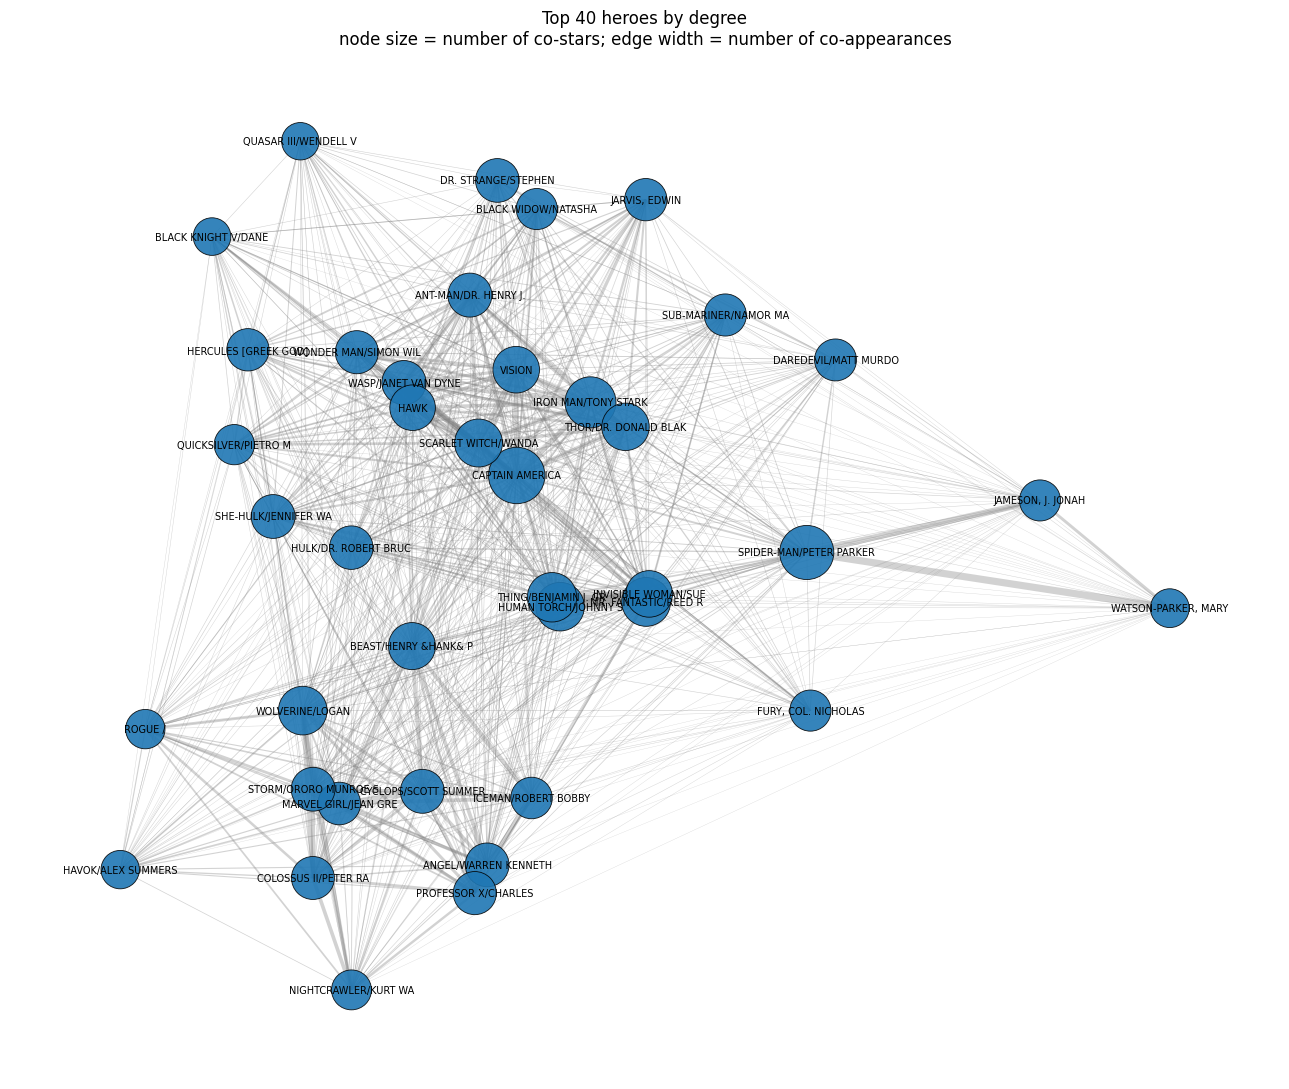

In [ ]:
TOP_K = 40

top_heroes = [hero for hero, _ in sorted(G.degree, key=lambda item: item[1], reverse=True)[:TOP_K]]
H = G.subgraph(top_heroes)

pos = nx.spring_layout(H, seed=42, weight="weight")

weights = [data["weight"] for _, _, data in H.edges(data=True)]
max_weight = max(weights)
max_degree = max(G.degree(hero) for hero in H)

print(f"Top {TOP_K} subgraph: {H.number_of_edges()} edges, density = {nx.density(H):.3f}")
print(f"Edge weights: min = {min(weights)}, max = {max_weight}")

plt.figure(figsize=(13, 11))
nx.draw_networkx_edges(
    H,
    pos,
    width=[0.2 + 6 * weight / max_weight for weight in weights],
    alpha=0.35,
    edge_color="gray",
)
nx.draw_networkx_nodes(
    H,
    pos,
    node_size=[150 + 1500 * G.degree(hero) / max_degree for hero in H],
    node_color="tab:blue",
    edgecolors="black",
    linewidths=0.6,
    alpha=0.9,
)
nx.draw_networkx_labels(H, pos, font_size=7)
plt.title(f"Top {TOP_K} heroes by degree\nnode size = number of co-stars; edge width = number of co-appearances")
plt.axis("off")
plt.tight_layout()
plt.show()

#### The whole giant component

Optional, because the layout of the giant component takes about one and a half minutes. Set `SHOW_FULL_GRAPH = True` and rerun the cell to draw it.

Layout call: 85.8 seconds


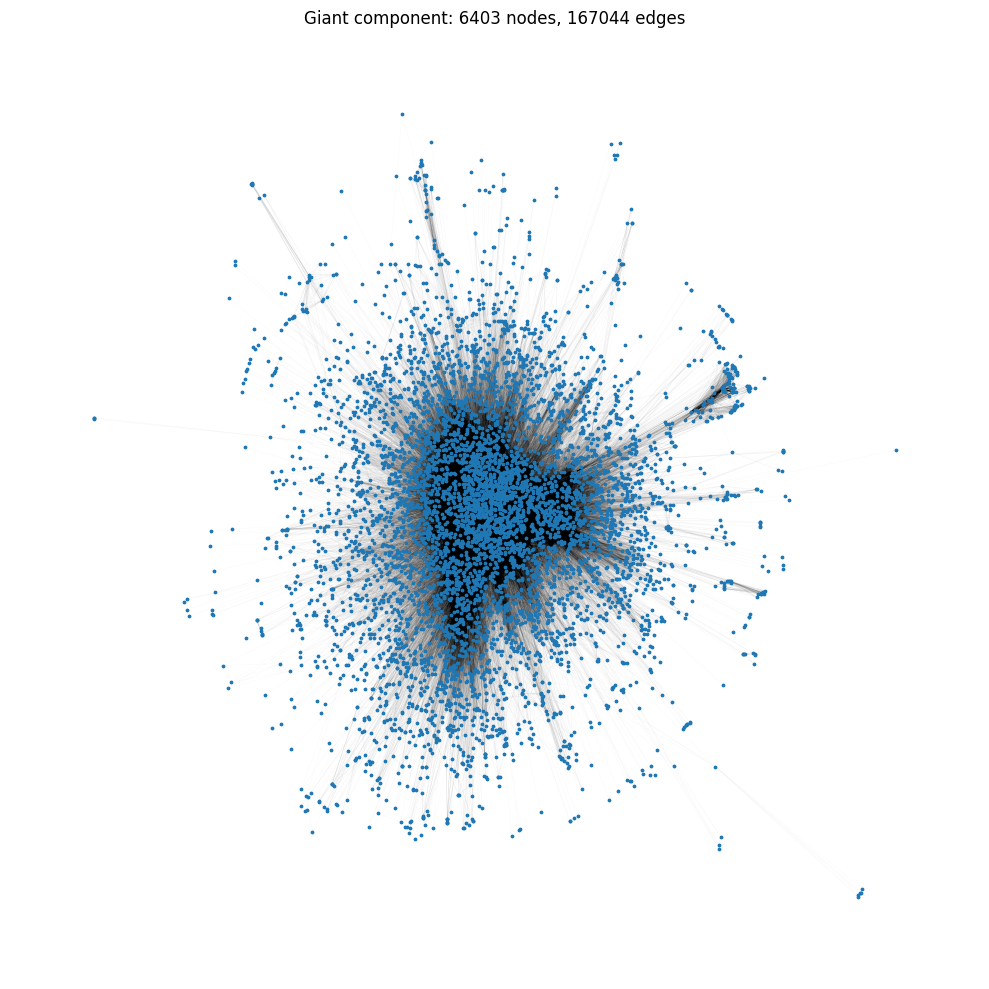

In [ ]:
SHOW_FULL_GRAPH = True

if SHOW_FULL_GRAPH:
    giant_graph = G.subgraph(max(nx.connected_components(G), key=len))

    t0 = perf_counter()
    pos_giant = nx.spring_layout(giant_graph, seed=42, weight=None)
    print(f"Layout call: {perf_counter() - t0:.1f} seconds")

    plt.figure(figsize=(10, 10))
    nx.draw_networkx_edges(giant_graph, pos_giant, width=0.3, alpha=0.03)
    nx.draw_networkx_nodes(giant_graph, pos_giant, node_size=3, node_color="tab:blue")
    plt.title(
        f"Giant component: {giant_graph.number_of_nodes()} nodes, "
        f"{giant_graph.number_of_edges()} edges"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: set SHOW_FULL_GRAPH = True to draw the whole giant component.")

## Analysis

TODO: analysis